# 01 · EDA and Model Comparison: NYC Yellow Taxi Trip Duration (January 2025)

This notebook covers the exploration behind the decisions in `src/` and the model results
tracked in MLflow:

1. **Inspect** the raw January 2025 data.
2. **Define the target** (`duration`) and justify the cleaning rules.
3. **Explore** what drives trip duration.
4. **Check for leakage**: why fare, tip and total are not used as features.
5. **Split**: train on Jan 1–24, validate on Jan 25–31.
6. **Compare models** logged in MLflow: baseline, Optuna-tuned, and full-data.

It reuses `src/data.py` and `src/features.py`, so the notebook and the training code apply
exactly the same cleaning and features.

In [1]:
import os
import sys
from pathlib import Path

# Run from the repo root so `src` imports and relative data paths work.
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, str(Path.cwd()))
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import DATA_PATH, MAX_DISTANCE, MAX_DURATION, MIN_DURATION, SPLIT_DATE, clean, load_raw, split
from src.features import FEATURES

plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Load and inspect the raw data

In [2]:
if not DATA_PATH.exists():
    load_raw()  # downloads the parquet file on first run
raw = pd.read_parquet(DATA_PATH)
print(f"{len(raw):,} trips x {raw.shape[1]} columns")
raw.head()

3,475,226 trips x 20 columns


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,1,2025-01-01 00:18:38,2025-01-01 00:26:59,1.00,1.60,1.00,N,229,237,1,10.00,3.50,0.50,3.00,0.00,1.00,18.00,2.50,0.00,0.00
1,1,2025-01-01 00:32:40,2025-01-01 00:35:13,1.00,0.50,1.00,N,236,237,1,5.10,3.50,0.50,2.02,0.00,1.00,12.12,2.50,0.00,0.00
2,1,2025-01-01 00:44:04,2025-01-01 00:46:01,1.00,0.60,1.00,N,141,141,1,5.10,3.50,0.50,2.00,0.00,1.00,12.10,2.50,0.00,0.00
3,2,2025-01-01 00:14:27,2025-01-01 00:20:01,3.00,0.52,1.00,N,244,244,2,7.20,1.00,0.50,0.00,0.00,1.00,9.70,0.00,0.00,0.00
4,2,2025-01-01 00:21:34,2025-01-01 00:25:06,3.00,0.66,1.00,N,244,116,2,5.80,1.00,0.50,0.00,0.00,1.00,8.30,0.00,0.00,0.00


In [3]:
summary = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_%": raw.isna().mean() * 100,
})
summary

,dtype,missing,missing_%
VendorID,int32,0,0.00
tpep_pickup_datetime,datetime64[us],0,0.00
tpep_dropoff_datetime,datetime64[us],0,0.00
passenger_count,float64,540149,15.54
trip_distance,float64,0,0.00
RatecodeID,float64,540149,15.54
store_and_fwd_flag,str,540149,15.54
PULocationID,int32,0,0.00
DOLocationID,int32,0,0.00
payment_type,int64,0,0.00


About **15.5%** of rows are missing `passenger_count`, `RatecodeID`, `store_and_fwd_flag`,
`congestion_surcharge` and `Airport_fee`, all in the same rows. Of these, only
`passenger_count` is a model feature, and it is filled with 1 (the most common value) in
`src/features.py`.

## 2. Define the target: `duration` in minutes

In [4]:
raw["duration"] = (raw["tpep_dropoff_datetime"] - raw["tpep_pickup_datetime"]).dt.total_seconds() / 60
raw["duration"].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99])

count   3,475,226.00
mean           15.02
std            38.71
min       -51,472.32
1%              0.67
5%              3.37
50%            11.70
95%            36.20
99%            58.92
max         5,626.32
Name: duration, dtype: float64

In [5]:
d = raw["duration"]
pd.Series({
    "negative duration": (d < 0).sum(),
    "under 1 min": (d < MIN_DURATION).sum(),
    "over 60 min": (d > MAX_DURATION).sum(),
    "over 24 hours": (d > 24 * 60).sum(),
    "share within 1-60 min": d.between(MIN_DURATION, MAX_DURATION).mean(),
}).to_frame("count / share")

,count / share
negative duration,124.00
under 1 min,"40,111.00"
over 60 min,"31,867.00"
over 24 hours,20.00
share within 1-60 min,0.98


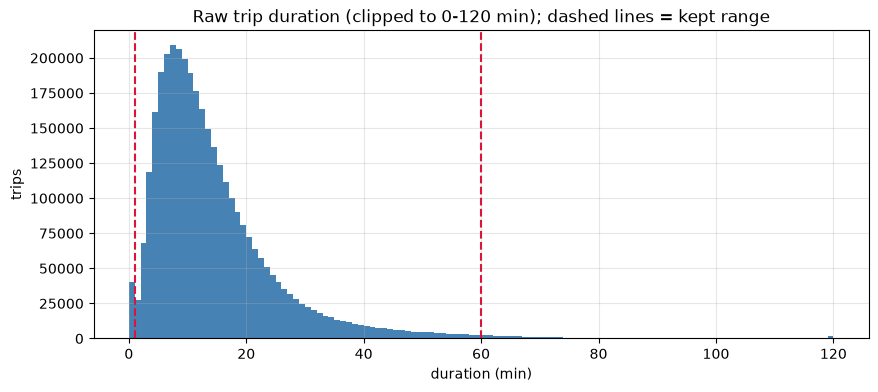

In [6]:
fig, ax = plt.subplots()
ax.hist(d.clip(0, 120), bins=120, color="steelblue")
for x in (MIN_DURATION, MAX_DURATION):
    ax.axvline(x, color="crimson", ls="--")
ax.set(title="Raw trip duration (clipped to 0-120 min); dashed lines = kept range",
       xlabel="duration (min)", ylabel="trips")
plt.show()

The data contains impossible durations: negative values (clock or recording errors) and
trips lasting days (meters left running). **97.9%** of trips fall between 1 and 60 minutes,
so that range is kept. Durations under 1 minute are mostly cancelled or test trips.

In [7]:
dist = raw["trip_distance"]
pd.Series({
    "zero distance": (dist == 0).sum(),
    f"over {MAX_DISTANCE} miles": (dist > MAX_DISTANCE).sum(),
    "max distance": dist.max(),
    "pickups outside January": (~raw["tpep_pickup_datetime"].between("2025-01-01", "2025-02-01", inclusive="left")).sum(),
}).to_frame("value")

,value
zero distance,"90,893.00"
over 100 miles,162.00
max distance,"276,423.57"
pickups outside January,22.00


Next, apply the same cleaning as training (`src.data.clean`):

In [8]:
df = clean(raw)
print(f"kept {len(df):,} of {len(raw):,} trips ({len(df) / len(raw):.1%})")
df["duration"].describe()

kept 3,339,084 of 3,475,226 trips (96.1%)


count   3,339,084.00
mean           14.20
std             9.77
min             1.00
25%             7.37
50%            11.67
75%            18.13
max            60.00
Name: duration, dtype: float64

## 3. What drives trip duration?

The plots use a 200k-row sample to keep them fast.

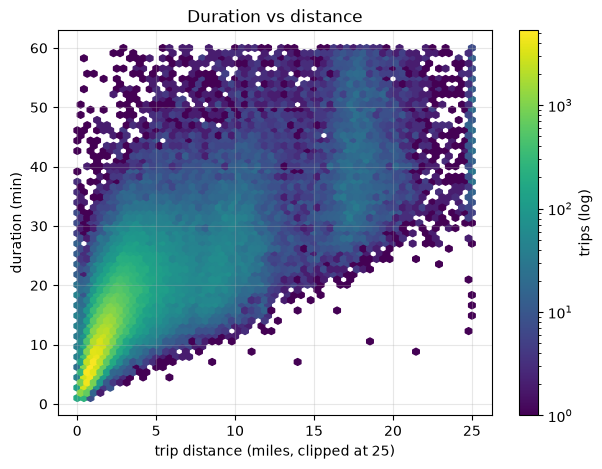

Pearson correlation, distance vs duration: 0.8


In [9]:
sample = df.sample(200_000, random_state=42)

fig, ax = plt.subplots(figsize=(7, 5))
hb = ax.hexbin(sample["trip_distance"].clip(upper=25), sample["duration"], gridsize=60, bins="log", cmap="viridis")
fig.colorbar(hb, label="trips (log)")
ax.set(title="Duration vs distance", xlabel="trip distance (miles, clipped at 25)", ylabel="duration (min)")
plt.show()
print("Pearson correlation, distance vs duration:", round(df["trip_distance"].corr(df["duration"]), 3))

Distance is by far the strongest signal. The vertical spread at any given distance comes
from traffic, which depends on **when** and **where** the trip happens:

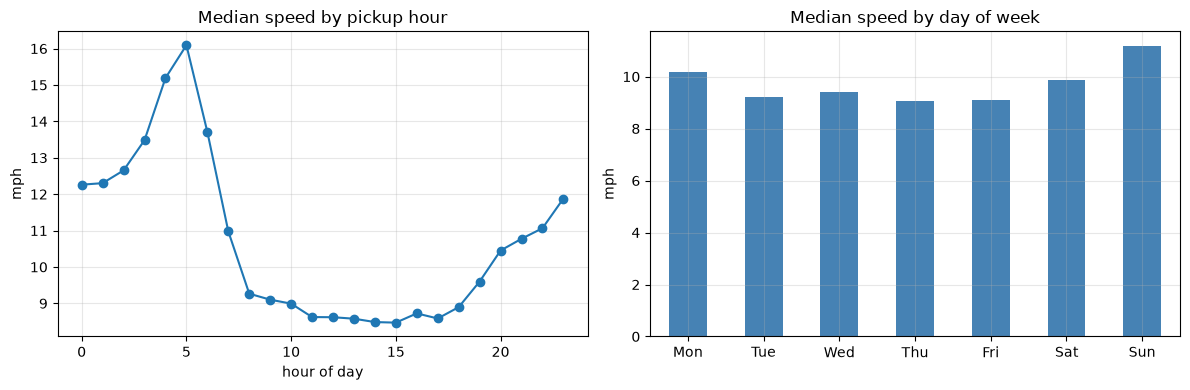

In [10]:
pickup = df["tpep_pickup_datetime"]
speed = df["trip_distance"] / (df["duration"] / 60)  # mph

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
speed.groupby(pickup.dt.hour).median().plot(ax=axes[0], marker="o")
axes[0].set(title="Median speed by pickup hour", xlabel="hour of day", ylabel="mph")
dow = speed.groupby(pickup.dt.day_of_week).median()
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dow.plot.bar(ax=axes[1], color="steelblue", rot=0)
axes[1].set(title="Median speed by day of week", ylabel="mph")
plt.tight_layout()
plt.show()

Speeds drop during the day and at the evening rush, and recover overnight. Weekends are
faster than weekdays. This is why `pickup_hour` and `pickup_dow` are features.

**Monday is unexpectedly fast.** The next cell breaks it down by date:

In [11]:
mondays = df[pickup.dt.day_of_week == 0]
mon_speed = speed[mondays.index].groupby(mondays["tpep_pickup_datetime"].dt.date).median()
print(mon_speed.round(2).to_string())
print("Tue-Fri median speed:", round(speed[pickup.dt.day_of_week.between(1, 4)].median(), 2))

tpep_pickup_datetime
2025-01-06    9.82
2025-01-13    9.76
2025-01-20   11.57
2025-01-27    9.58
Tue-Fri median speed: 9.19


**Monday, Jan 20 was Martin Luther King Jr. Day.** Holiday traffic was much lighter
(about 11.6 mph vs 9.6–9.8 mph on the other Mondays), which pulls up the Monday average.
Day of week alone cannot tell a holiday from a normal Monday, so a **holiday flag** is a
concrete feature to add next. Ordinary Mondays are still slightly faster than
Tuesday–Friday.

In [12]:
top = df["PULocationID"].value_counts().head(10).index
by_zone = (df[df["PULocationID"].isin(top)]
           .assign(speed=speed)
           .groupby("PULocationID")
           .agg(trips=("duration", "size"), median_duration=("duration", "median"),
                median_distance=("trip_distance", "median"), median_speed=("speed", "median"))
           .sort_values("trips", ascending=False))
by_zone

,trips,median_duration,median_distance,median_speed
PULocationID,,,,
161,165650,11.80,1.50,8.10
237,160852,8.95,1.20,8.54
236,152671,9.30,1.40,9.00
132,127843,36.00,17.06,26.10
230,122382,11.98,1.53,8.66
186,117028,12.73,1.50,8.21
162,115149,11.50,1.50,8.51
142,108551,10.13,1.60,9.68
239,94393,9.82,1.60,9.70


The busiest pickup zones differ a lot in typical distance and speed. Airport zones
(132 = JFK, 138 = LaGuardia) have long, fast trips, while Midtown and Upper East Side
zones have short, slow ones. This is why the zone IDs are features.

In [13]:
pc = df["passenger_count"].fillna(1).clip(upper=6)
df.groupby(pc)["duration"].agg(["size", "median"]).rename_axis("passenger_count")

,size,median
passenger_count,,
0.00,23434,10.52
1.00,2745749,11.63
2.00,396418,11.88
3.00,88703,12.00
4.00,55620,12.97
5.00,17434,10.65
6.00,11726,10.63


Passenger count barely changes duration. It is kept because it is cheap, but the model
gives it almost no weight (see the feature importances below).

## 4. Leakage check: why fare, tip and total are excluded

These columns correlate strongly with duration, but they are **computed from the finished
trip**: the metered fare includes time charges. A prediction API is called *before* the
trip, so these values don't exist yet when the prediction is needed.

In [14]:
cols = ["trip_distance", "fare_amount", "total_amount", "tip_amount", "tolls_amount"]
# Re-load with the money columns; clean() applies the same filters as training.
cleaned_full = clean(pd.read_parquet(DATA_PATH, columns=[
    "tpep_pickup_datetime", "tpep_dropoff_datetime", "PULocationID", "DOLocationID",
    "trip_distance", "passenger_count", *cols[1:]]))
corr = pd.DataFrame({
    "pearson": cleaned_full[cols + ["duration"]].corr()["duration"],
    "spearman (rank)": cleaned_full[cols + ["duration"]].corr(method="spearman")["duration"],
}).drop("duration").sort_values("spearman (rank)", ascending=False)
corr

,pearson,spearman (rank)
fare_amount,0.02,0.87
trip_distance,0.80,0.85
total_amount,0.03,0.83
tolls_amount,0.43,0.33
tip_amount,0.46,0.29


In [15]:
fare = cleaned_full["fare_amount"]
print(f"negative fares: {(fare < 0).sum():,}   max fare: ${fare.max():,.0f}")

negative fares: 126,217   max fare: $863,372


The two correlation measures disagree, and the reason matters:

- **Pearson** says fare barely relates to duration (about 0.02). This is an artefact of
  bad data. More than 126k negative fares (refunds and voids) and one fare of over
  $860,000 dominate a measure based on squared deviations.
- **Spearman**, which uses ranks and so isn't thrown off by extreme values, shows that
  `fare_amount` tracks duration **more closely than trip distance does** (about 0.87 vs
  0.85). That makes sense, because NYC meters charge for time spent in slow traffic.

So fare would be a very strong feature offline, but it is only known once the trip is
over. Using it would give a great validation RMSE and a model that cannot be used before
the trip starts.

**Features used:** `PULocationID`, `DOLocationID`, `trip_distance`, `passenger_count`, `pickup_hour`, `pickup_dow`.

## 5. Train / validation split (by time)

In [16]:
train_df, val_df = split(df)
pd.DataFrame({
    "trips": [len(train_df), len(val_df)],
    "from": [train_df.tpep_pickup_datetime.min(), val_df.tpep_pickup_datetime.min()],
    "to": [train_df.tpep_pickup_datetime.max(), val_df.tpep_pickup_datetime.max()],
    "mean duration": [train_df.duration.mean(), val_df.duration.mean()],
}, index=["train", "validation"])

,trips,from,to,mean duration
train,2540706,2025-01-01 00:00:02,2025-01-24 23:59:59,14.18
validation,798378,2025-01-25 00:00:00,2025-01-31 23:59:59,14.27


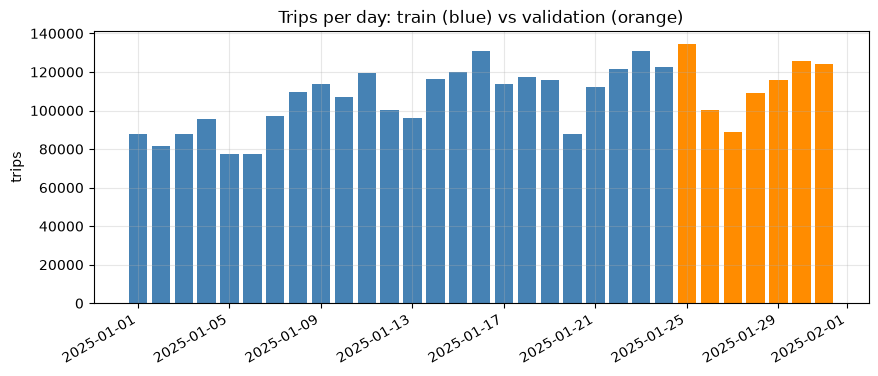

In [17]:
daily = df.groupby(df["tpep_pickup_datetime"].dt.date).size()
fig, ax = plt.subplots()
ax.bar(daily.index, daily.values, color=["steelblue" if pd.Timestamp(x) < SPLIT_DATE else "darkorange" for x in daily.index])
ax.set(title="Trips per day: train (blue) vs validation (orange)", ylabel="trips")
fig.autofmt_xdate()
plt.show()

Splitting by date simulates the real task, which is predicting trips that happen
*after* the training data. Validation also includes a full weekend, so it isn't skewed
towards weekdays.

## 6. Model comparison (from MLflow)

All runs are logged to the local `mlflow.db` (experiment `nyc-taxi-duration`). The cells
below read the top-level runs. The Optuna search's 25 individual trials are stored as
nested child runs and are excluded here.

In [18]:
import mlflow

mlflow.set_tracking_uri("sqlite:///mlflow.db")
runs = mlflow.search_runs(experiment_names=["nyc-taxi-duration"],
                          filter_string="attributes.status = 'FINISHED'")
runs = runs[runs["tags.mlflow.parentRunId"].isna()] if "tags.mlflow.parentRunId" in runs else runs
cols = {"tags.mlflow.runName": "run", "params.train_rows": "train_rows",
        "metrics.rmse_train": "rmse_train", "metrics.rmse_val": "rmse_val",
        "metrics.model_size_mb": "size_mb"}
# The first baseline run was logged before model size was tracked; its file is 249 MB.
table = runs[list(cols)].rename(columns=cols).sort_values("rmse_val", ascending=False).reset_index(drop=True)
table

,run,train_rows,rmse_train,rmse_val,size_mb
0,rf-baseline,500000,3.36,4.10,NaN
1,rf-optuna,500000,2.87,4.02,"1,681.36"
2,rf-baseline-fulldata,2540706,3.50,3.96,729.07


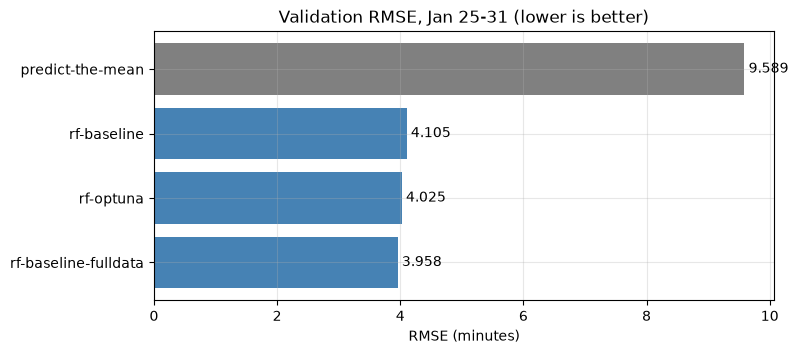

In [19]:
mean_rmse = runs["metrics.rmse_val_mean_baseline"].dropna().iloc[0]
plot_df = pd.concat([pd.DataFrame({"run": ["predict-the-mean"], "rmse_val": [mean_rmse]}), table[["run", "rmse_val"]]])

fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.barh(plot_df["run"], plot_df["rmse_val"], color=["grey"] + ["steelblue"] * (len(plot_df) - 1))
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.invert_yaxis()
ax.set(title="Validation RMSE, Jan 25-31 (lower is better)", xlabel="RMSE (minutes)")
plt.show()

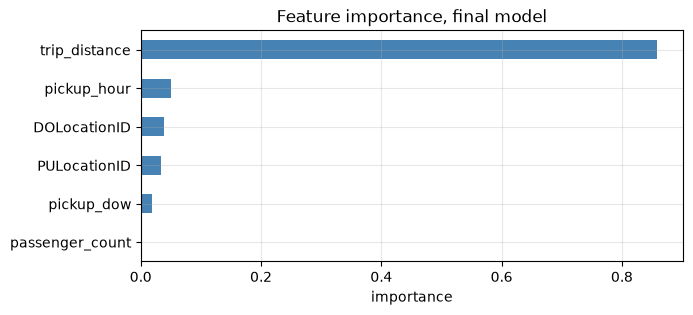

In [20]:
final = runs[runs["tags.mlflow.runName"] == "rf-baseline-fulldata"].iloc[0]
imp = pd.Series(mlflow.artifacts.load_dict(f"runs:/{final.run_id}/feature_importances.json")).sort_values()
ax = imp.plot.barh(color="steelblue", figsize=(7, 3))
ax.set(title="Feature importance, final model", xlabel="importance")
plt.show()

Optuna best params: {'min_samples_leaf': '3', 'max_features': '0.5', 'n_estimators': '150', 'max_depth': '26'}


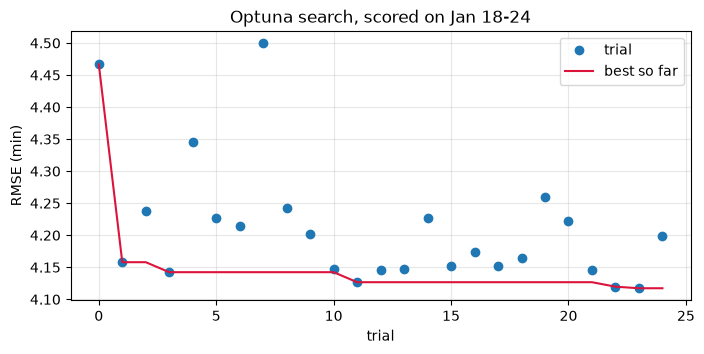

In [21]:
tuned = runs[runs["tags.mlflow.runName"] == "rf-optuna"].iloc[0]
print("Optuna best params:", {k.removeprefix("params.best_"): tuned[k] for k in runs if k.startswith("params.best_") and pd.notna(tuned[k])})

trials = mlflow.search_runs(experiment_names=["nyc-taxi-duration"],
                            filter_string=f"tags.mlflow.parentRunId = '{tuned.run_id}'")
fig, ax = plt.subplots(figsize=(8, 3.5))
order = trials.sort_values("start_time")
ax.plot(range(len(order)), order["metrics.rmse_tune_val"], "o", label="trial")
ax.plot(range(len(order)), order["metrics.rmse_tune_val"].cummin(), "-", color="crimson", label="best so far")
ax.set(title="Optuna search, scored on Jan 18-24", xlabel="trial", ylabel="RMSE (min)")
ax.legend()
plt.show()

## Conclusions

- **Cleaning:** keeping 1–60 minute trips with a valid distance retains about 96% of the
  data and removes clearly broken records.
- **Signal:** distance dominates, with about 85% of feature importance. Hour, day of week
  and zones capture traffic and add the rest.
- **Leakage:** fare and total amounts are excluded because they are only known after the
  trip ends.
- **Models:**
  - The final model (baseline settings trained on all 2.54M training trips) reaches a
    validation RMSE of **3.958 min**, against 9.589 for always predicting the average.
  - **Optuna tuning helped less than more data:** about 2% better than the baseline, for
    a 7× larger model.
- **Next steps:** better features (historical duration for each zone pair, a holiday flag
  as the MLK Day check shows, weather), gradient boosting, and predicting `log(duration)`.